# 项目三：商品详情页新版评价卡片 A/B 测试分析

数据是固定随机种子生成的**虚构教学数据**（`data/abtest/ab_experiment.csv`，12000 名用户，14 天），不代表真实公司实验。你将完整走完：SRM 分流校验 → 总体指标评估 → 护栏指标检验 → 新老客异质性拆解 → 决策建议。

请选择 `Python (da-course)` 内核，从本包 `notebooks/` 目录打开。

> **这是参考答案版**，保留完整示例与解法。代码格下方的输出会在运行后出现。
> 建议先在 `notebooks/` 文件夹里的学生版自己做一遍，卡住了再来这里对照。

In [1]:
import sys
sys.path.insert(0, "..")
from dacheck import check, hint, setup_chinese_font
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

## 1. 读取实验数据与基础质量体检

In [2]:
ab = pd.read_csv("../data/abtest/ab_experiment.csv", encoding="utf-8-sig")
assert ab["user_id"].is_unique
assert set(ab["group"]) == {"control", "treatment"}
assert (ab["converted"] <= ab["clicked"]).all()
assert (ab.loc[ab["converted"].eq(0), "order_amount"] == 0).all()
print("实验数据质量体检通过：", ab.shape)
ab.head()

实验数据质量体检通过： (12000, 9)


,user_id,group,device,is_new_user,exposure_date,clicked,converted,order_amount,page_load_ms
0,AB00001,control,iOS,1,2025-10-10,0,0,0.0,388
1,AB00002,control,iOS,1,2025-10-09,0,0,0.0,397
2,AB00003,treatment,Android,1,2025-10-06,1,0,0.0,423
3,AB00004,treatment,Android,0,2025-10-08,0,0,0.0,526
4,AB00005,treatment,iOS,1,2025-10-14,1,0,0.0,401


## 2. SRM（样本比例失衡）与均衡性校验

实验预设 50/50 分流。在看转化率之前，先用卡方拟合优度检验（`stats.chisquare`）确认实际流量没有严重偏离 50/50。

练习 P-3.1：计算 `control_n, treatment_n, srm_chi2, srm_p`，存入字典 `p3_srm`。

In [3]:
c_n = int((ab["group"] == "control").sum())
t_n = int((ab["group"] == "treatment").sum())
srm_chi2, srm_p = stats.chisquare([c_n, t_n])
p3_srm = {
    "control_n": c_n,
    "treatment_n": t_n,
    "srm_chi2": float(srm_chi2),
    "srm_p": float(srm_p),
}
check("P-3.1", p3_srm)

True

## 3. 总体核心指标与护栏指标对比

练习 P-3.2：按 `group` 汇总 `users, click_rate, conv_rate, avg_load_ms, arpu`（`order_amount` 均值），按 `group` 升序排列。

In [4]:
p3_overview = (
    ab.groupby("group", as_index=False)
    .agg(
        users=("user_id", "size"),
        click_rate=("clicked", "mean"),
        conv_rate=("converted", "mean"),
        avg_load_ms=("page_load_ms", "mean"),
        arpu=("order_amount", "mean"),
    )
    .sort_values("group")
    .reset_index(drop=True)
)
check("P-3.2", p3_overview)

True

## 4. 主指标转化率检验与护栏指标耗时检验

练习 P-3.3：计算主指标转化率 `control_rate, treatment_rate, lift` 以及卡方检验（`correction=False`）`p_value`。

In [5]:
r_all = ab.groupby("group")["converted"].mean()
_, p_all, _, _ = stats.chi2_contingency(pd.crosstab(ab["group"], ab["converted"]), correction=False)
p3_conv = {
    "control_rate": float(r_all["control"]),
    "treatment_rate": float(r_all["treatment"]),
    "lift": float(r_all["treatment"] - r_all["control"]),
    "p_value": float(p_all),
}
check("P-3.3", p3_conv)

True

练习 P-3.4：用 Welch t 检验（`equal_var=False`）评估护栏指标 `page_load_ms`，输出 `control_ms, treatment_ms, diff_ms, p_value`。

In [6]:
c_ms = ab.loc[ab["group"].eq("control"), "page_load_ms"]
t_ms = ab.loc[ab["group"].eq("treatment"), "page_load_ms"]
_, p_ms = stats.ttest_ind(t_ms, c_ms, equal_var=False)
p3_guard = {
    "control_ms": float(c_ms.mean()),
    "treatment_ms": float(t_ms.mean()),
    "diff_ms": float(t_ms.mean() - c_ms.mean()),
    "p_value": float(p_ms),
}
check("P-3.4", p3_guard)

True

## 5. 新老客异质性拆解与已转化客单价

练习 P-3.5：按 `is_new_user`（0 老客 / 1 新客）分别计算 `control_rate, treatment_rate, lift, p_value`（卡方检验 `correction=False`），按 `is_new_user` 升序排列。

In [7]:
seg_rows = []
for nu, sub in ab.groupby("is_new_user"):
    r_s = sub.groupby("group")["converted"].mean()
    _, p_s, _, _ = stats.chi2_contingency(pd.crosstab(sub["group"], sub["converted"]), correction=False)
    seg_rows.append({
        "is_new_user": int(nu),
        "control_rate": float(r_s["control"]),
        "treatment_rate": float(r_s["treatment"]),
        "lift": float(r_s["treatment"] - r_s["control"]),
        "p_value": float(p_s),
    })
p3_seg = pd.DataFrame(seg_rows).sort_values("is_new_user").reset_index(drop=True)
check("P-3.5", p3_seg)

True

绘制新老客分组转化率对比柱状图（独立示例）。

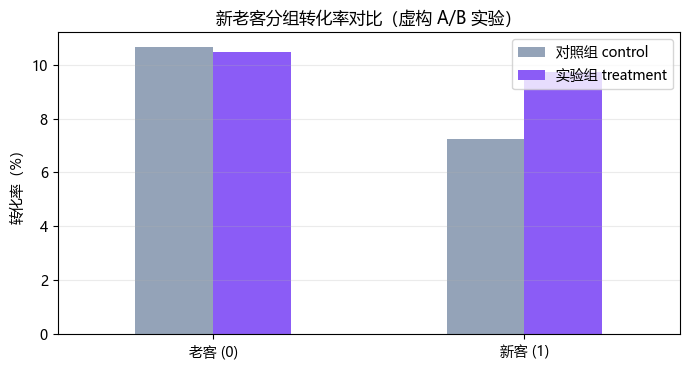

In [8]:
setup_chinese_font()
piv_plot = ab.groupby(["is_new_user", "group"])["converted"].mean().unstack() * 100
piv_plot.index = ["老客 (0)", "新客 (1)"]
fig, ax = plt.subplots(figsize=(7, 3.8))
piv_plot[["control", "treatment"]].plot(kind="bar", ax=ax, color=["#94a3b8", "#8b5cf6"], rot=0)
ax.set(title="新老客分组转化率对比（虚构 A/B 实验）", xlabel="", ylabel="转化率（%）")
ax.legend(["对照组 control", "实验组 treatment"])
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

练习 P-3.6：仅在已转化用户（`converted == 1`）中比较两组 `order_amount` 均值与 Welch t 检验 `p_value`，输出 `control_aov, treatment_aov, diff_aov, p_value`。

In [9]:
conv_only = ab.loc[ab["converted"].eq(1)]
c_aov = conv_only.loc[conv_only["group"].eq("control"), "order_amount"]
t_aov = conv_only.loc[conv_only["group"].eq("treatment"), "order_amount"]
_, p_aov = stats.ttest_ind(t_aov, c_aov, equal_var=False)
p3_aov = {
    "control_aov": float(c_aov.mean()),
    "treatment_aov": float(t_aov.mean()),
    "diff_aov": float(t_aov.mean() - c_aov.mean()),
    "p_value": float(p_aov),
}
check("P-3.6", p3_aov)

True